# Web Scraping & Product Price Analysis System

**Technologies:** Python, BeautifulSoup, Pandas, Matplotlib
**Data Source:** Books to Scrape

Install + Import Libraries

In [2]:
!pip install requests beautifulsoup4 pandas matplotlib

import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

Scrape the Website

In [4]:
import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"

response = requests.get(url)
soup = BeautifulSoup(response.content, "html.parser")

books = soup.find_all("article", class_="product_pod")

data = []

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for book in books:

    # Book name
    name = book.h3.a["title"]

    # Price
    price = book.find("p", class_="price_color").text.strip()

    # Keep only numbers and decimal point
    price = float(
        price.replace("£", "")
             .replace("Â", "")
             .strip()
    )

    # Rating
    rating_text = book.find("p", class_="star-rating")["class"][1]
    rating = rating_map[rating_text]

    data.append([name, price, rating])

print("Books scraped:", len(data))

Books scraped: 20


Create & Clean Dataset

In [5]:
import pandas as pd

df = pd.DataFrame(
    data,
    columns=["Product Name", "Price", "Rating"]
)

df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

df.to_csv("products.csv", index=False)

display(df)

,Product Name,Price,Rating
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5
5,The Requiem Red,22.65,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4
7,The Coming Woman: A Novel Based on the Life of...,17.93,3
8,The Boys in the Boat: Nine Americans and Their...,22.60,4
9,The Black Maria,52.15,1


Data Analysis

In [6]:
print("Total Products:", len(df))
print("Average Price: £", round(df["Price"].mean(), 2))
print("Minimum Price: £", round(df["Price"].min(), 2))
print("Maximum Price: £", round(df["Price"].max(), 2))
print("Average Rating:", round(df["Rating"].mean(), 2))

print("\nMost Expensive Book:")
display(df.loc[[df["Price"].idxmax()]])

print("\nHighest Rated Books:")
display(df[df["Rating"] == df["Rating"].max()])

Total Products: 20
Average Price: £ 38.05
Minimum Price: £ 13.99
Maximum Price: £ 57.25
Average Rating: 2.85

Most Expensive Book:


,Product Name,Price,Rating
15,Our Band Could Be Your Life: Scenes from the A...,57.25,3



Highest Rated Books:


,Product Name,Price,Rating
4,Sapiens: A Brief History of Humankind,54.23,5
12,Set Me Free,17.46,5
13,Scott Pilgrim's Precious Little Life (Scott Pi...,52.29,5
14,Rip it Up and Start Again,35.02,5


Price Comparison Graph

/tmp/ipykernel_3730/2581606268.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


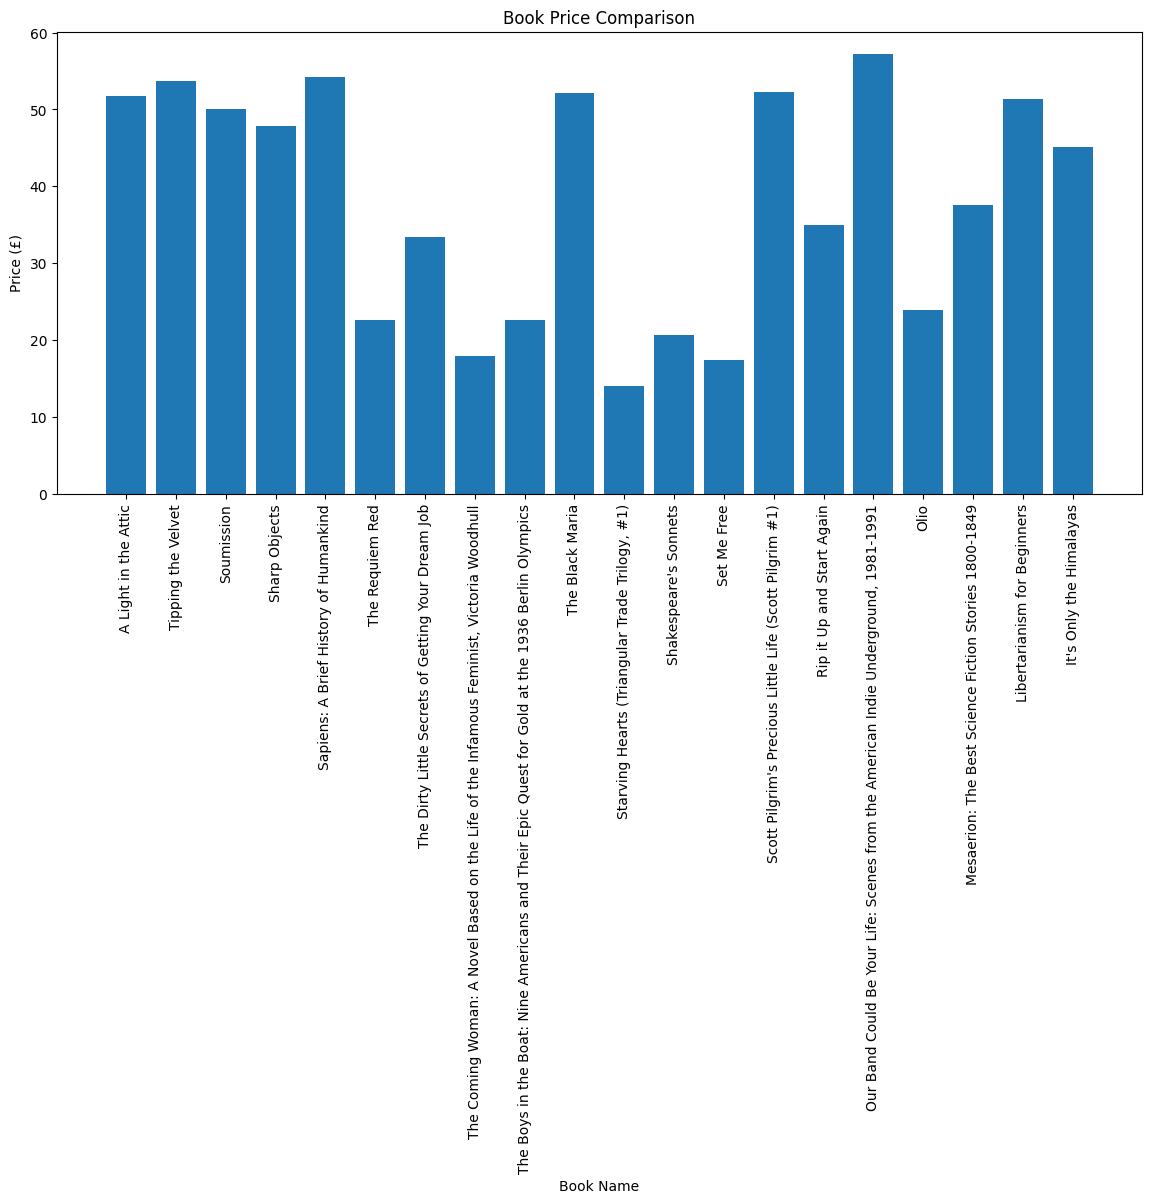

In [7]:
plt.figure(figsize=(14, 6))

plt.bar(df["Product Name"], df["Price"])

plt.xlabel("Book Name")
plt.ylabel("Price (£)")
plt.title("Book Price Comparison")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

Rating vs Price Graph

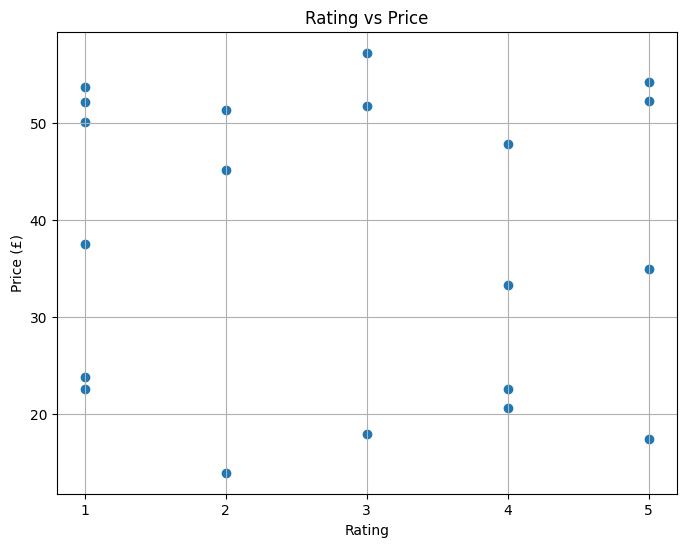

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(df["Rating"], df["Price"])

plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.title("Rating vs Price")

plt.xticks([1, 2, 3, 4, 5])
plt.grid(True)

plt.show()

Final Results

In [9]:
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 40)

print("Dataset saved as: products.csv")
print("Total products analyzed:", len(df))
print("Average price: £", round(df["Price"].mean(), 2))
print("Average rating:", round(df["Rating"].mean(), 2))

correlation = df["Price"].corr(df["Rating"])
print("Price-Rating correlation:", round(correlation, 3))

PROJECT COMPLETED SUCCESSFULLY
Dataset saved as: products.csv
Total products analyzed: 20
Average price: £ 38.05
Average rating: 2.85
Price-Rating correlation: -0.076
